In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shuvoalok/raf-db-dataset/test_labels.csv
/kaggle/input/datasets/shuvoalok/raf-db-dataset/train_labels.csv
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2941_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2717_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2499_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2724_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2935_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2419_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2779_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2566_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2805_aligned.jpg
/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test/7/test_2495_aligned.jpg
/kaggle/input/dataset

### Library

In [2]:
!pip install facenet-pytorch --no-deps

ERROR: Could not find a version that satisfies the requirement facenet-pytorch (from versions: none)
ERROR: No matching distribution found for facenet-pytorch


In [3]:
import copy
from collections import Counter
import os
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
import timm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Menggunakan device: {device}')

Menggunakan device: cuda


### TEMUKAN PATH DATASET RAF-DB

In [20]:
input_dir = Path('/kaggle/input')
dataset_path = None

for p in input_dir.rglob('datasets/shuvoalok/raf-db-dataset'):  # Sesuaikan nama folder RAF-DB di kaggle-mu
  if p.is_dir():
    dataset_path = p
    break

# Fallback pencarian umum jika namanya sedikit berbeda
if not dataset_path:
  for p in input_dir.rglob('*raf*'):
    if p.is_dir():
      dataset_path = p
      break

if dataset_path:
  DATA_DIR = dataset_path
  print(f'Berhasil menemukan dataset RAF-DB di: {DATA_DIR}')
else:
  raise FileNotFoundError(
      'Folder dataset RAF-DB tidak ditemukan! Pastikan sudah di-add ke Kaggle.'
  )

# Tentukan direktori train dan test
train_dir = DATA_DIR / 'DATASET/train'
test_dir = DATA_DIR / 'DATASET/test'

# Jika struktur foldernya langsung train/test di root
if not train_dir.exists():
  # Cek struktur alternatif
  subdirs = [x for x in DATA_DIR.iterdir() if x.is_dir()]
  print('Subfolder yang tersedia:', subdirs)

Berhasil menemukan dataset RAF-DB di: /kaggle/input/datasets/shuvoalok/raf-db-dataset


### DATA AUGMENTATION & TRANSFORM

In [22]:
# ==========================================
# 1. DATA TRANSFORMS
# ==========================================
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(8),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
}

# ==========================================
# 2. TARGET TRANSFORM & KELAS MAPPING (DIGABUNGKAN)
# ==========================================
# Definisikan urutan teks kelas yang kamu inginkan (Indeks 0 s.d. 6)
class_names = [
    'surprise',  # Indeks 0 (mewakili folder '1')
    'fear',      # Indeks 1 (mewakili folder '2')
    'disgust',   # Indeks 2 (mewakili folder '3')
    'happy',     # Indeks 3 (mewakili folder '4')
    'sad',       # Indeks 4 (mewakili folder '5')
    'angry',     # Indeks 5 (mewakili folder '6')
    'neutral',   # Indeks 6 (mewakili folder '7')
]

# Ambil daftar folder asli secara otomatis
temp_dataset = datasets.ImageFolder(train_dir)
raw_classes = temp_dataset.classes  # Biasanya ['1', '2', '3', '4', '5', '6', '7']

# Fungsi untuk menerjemahkan angka folder asli ke indeks baru (0-6)
def custom_target_transform(target_idx):
    folder_name = raw_classes[target_idx]
    mapping = {
        '1': 0,
        '2': 1,
        '3': 2,
        '4': 3,
        '5': 4,
        '6': 5,
        '7': 6,
    }
    return mapping[folder_name]

# Buat image_datasets dengan target_transform terintegrasi
image_datasets = {
    'train': datasets.ImageFolder(
        train_dir,
        transform=data_transforms['train'],
        target_transform=custom_target_transform,
    ),
    'test': datasets.ImageFolder(
        test_dir,
        transform=data_transforms['test'],
        target_transform=custom_target_transform,
    ),
}

print('Daftar Kelas Emosi Baru (Teks):', class_names)

dataloaders = {
    x: DataLoader(
        image_datasets[x], batch_size=32, shuffle=(x == 'train'), num_workers=2
    )
    for x in ['train', 'test']
}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'test']}

Daftar Kelas Emosi Baru (Teks): ['surprise', 'fear', 'disgust', 'happy', 'sad', 'angry', 'neutral']


### PENANGANAN CLASS IMBALANCE (CLASS WEIGHTS)

In [23]:
train_labels = image_datasets['train'].targets
class_counts = Counter(train_labels)
total_samples = len(train_labels)

class_weights = [total_samples / class_counts[i] for i in range(len(class_names))]
class_weights = torch.FloatTensor(class_weights).to(device)

### INISIALISASI MODEL (MobileNetV3-Large)

In [26]:
model = timm.create_model(
    'tf_efficientnetv2_s', pretrained=True, num_classes=len(class_names)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-2)

num_epochs = 20
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=num_epochs, eta_min=1e-6
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

### TRAINING LOOP

In [27]:
def train_model(
    model, criterion, optimizer, scheduler, num_epochs=20, patience=5
):
  since = time.time()
  best_model_wts = copy.deepcopy(model.state_dict())
  best_acc = 0.0
  trigger_times = 0

  for epoch in range(num_epochs):
    print(f'\nEpoch {epoch+1}/{num_epochs}')
    print('-' * 25)

    for phase in ['train', 'test']:  # Menggunakan train & test (sebagai validasi)
      if phase == 'train':
        model.train()
      else:
        model.eval()

      running_loss = 0.0
      running_corrects = 0

      for inputs, labels in dataloaders[phase]:
        inputs = inputs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()

        with torch.set_grad_enabled(phase == 'train'):
          outputs = model(inputs)
          _, preds = torch.max(outputs, 1)
          loss = criterion(outputs, labels)

          if phase == 'train':
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

      epoch_loss = running_loss / dataset_sizes[phase]
      epoch_acc = running_corrects.double() / dataset_sizes[phase]

      print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

      if phase == 'test':
        scheduler.step()  # CosineAnnealingLR step per epoch
        current_lr = optimizer.param_groups[0]['lr']
        print(f'Current Learning Rate: {current_lr:.6f}')

        if epoch_acc > best_acc:
          best_acc = epoch_acc
          best_model_wts = copy.deepcopy(model.state_dict())
          trigger_times = 0
        else:
            trigger_times += 1
            print(f'-> EarlyStopping Counter: {trigger_times}/{patience}')

    if trigger_times >= patience:
      print(f'\nEarly stopping diaktifkan pada epoch {epoch+1}!')
      break

  time_elapsed = time.time() - since
  print(f'\nTraining selesai dalam {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
  print(f'Akurasi Validasi/Test Terbaik: {best_acc:.4f}')

  model.load_state_dict(best_model_wts)
  return model


print('\n[INFO] Memulai training MobileNetV3 dengan RAF-DB...')
model = train_model(
    model, criterion, optimizer, scheduler, num_epochs=20, patience=5
)


[INFO] Memulai training MobileNetV3 dengan RAF-DB...

Epoch 1/20
-------------------------
Train Loss: 1.9971 Acc: 0.4652
Test Loss: 1.1205 Acc: 0.5779
Current Learning Rate: 0.000199

Epoch 2/20
-------------------------
Train Loss: 0.8597 Acc: 0.7028
Test Loss: 0.8513 Acc: 0.6897
Current Learning Rate: 0.000195

Epoch 3/20
-------------------------
Train Loss: 0.5775 Acc: 0.7939
Test Loss: 0.7035 Acc: 0.7409
Current Learning Rate: 0.000189

Epoch 4/20
-------------------------
Train Loss: 0.3940 Acc: 0.8489
Test Loss: 0.6591 Acc: 0.7800
Current Learning Rate: 0.000181

Epoch 5/20
-------------------------
Train Loss: 0.2905 Acc: 0.8886
Test Loss: 0.7218 Acc: 0.7692
Current Learning Rate: 0.000171
-> EarlyStopping Counter: 1/5

Epoch 6/20
-------------------------
Train Loss: 0.1965 Acc: 0.9209
Test Loss: 0.6964 Acc: 0.7976
Current Learning Rate: 0.000159

Epoch 7/20
-------------------------
Train Loss: 0.1719 Acc: 0.9382
Test Loss: 0.9329 Acc: 0.7402
Current Learning Rate: 0.000146

### Evaluasi & Confusion Matrix


[INFO] Menjalankan evaluasi akhir pada Test Set...
CLASSIFICATION REPORT
              precision    recall  f1-score   support

    surprise     0.8410    0.8359    0.8384       329
        fear     0.7302    0.6216    0.6715        74
     disgust     0.5629    0.5312    0.5466       160
       happy     0.9526    0.8987    0.9249      1185
         sad     0.8054    0.8138    0.8096       478
       angry     0.7247    0.7963    0.7588       162
     neutral     0.7660    0.8426    0.8025       680

    accuracy                         0.8351      3068
   macro avg     0.7690    0.7629    0.7646      3068
weighted avg     0.8386    0.8351    0.8359      3068



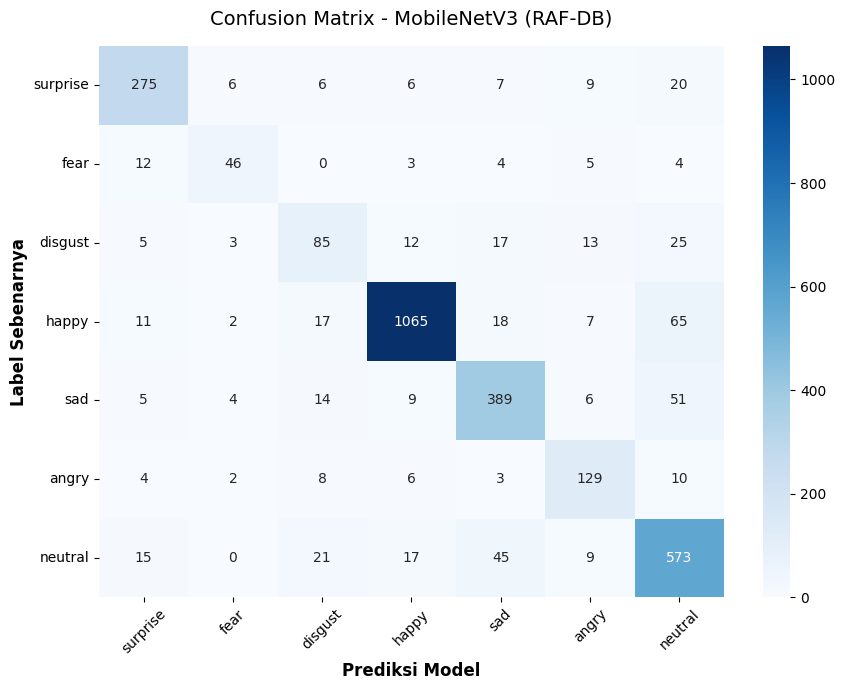

In [28]:
print('\n[INFO] Menjalankan evaluasi akhir pada Test Set...')
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in dataloaders['test']:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Cetak Classification Report (Precision, Recall, F1-Score)
print('=' * 65)
print('CLASSIFICATION REPORT')
print('=' * 65)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# Visualisasi Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Prediksi Model', fontsize=12, fontweight='bold')
plt.ylabel('Label Sebenarnya', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix - MobileNetV3 (RAF-DB)', fontsize=14, pad=15)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

### Simpan modeel

In [29]:
# Simpan model ke file .pth
torch.save(model.state_dict(), 'tf_efficientnetv2_s_rafdb_expression.pth')
print('[INFO] Model berhasil disimpan sebagai mobilenetv3_rafdb_expression.pth')

[INFO] Model berhasil disimpan sebagai mobilenetv3_rafdb_expression.pth
